# cases

Disease level retrieval, graph context, and training controls on the PrimeKG development split. Includes case rankings, recorded conflicting relations, subgroup comparisons, and ranking-cutoff sensitivity.

```
data    primekg 2.1
split   development / 136 diseases / 7,957 drugs
runs    6 / 120 epochs / seed 101
source  cda583e5a903
```

In [1]:
BUCKET = "hf://buckets/exapt-lab/hangar/runs"
DATA_SHA = "a29db6bb7019eefa4fd93d7b771f212cc88014a1"
RUNS = (
    "rgcn-lsep-total-n08",
    "rgcn-lsep-relation-n08",
    "rgcn-lsep-relation-n32",
    "rgcn-lsep-relation-n64",
    "rgcn-bce-relation-n32",
    "rgcn-bpr-relation-n32",
)

CUTS = (1, 5, 10, 20)
BOOTSTRAP_SEED = 163
BOOTSTRAP_SAMPLES = 20_000

In [2]:
import csv
import json
import math
import shutil
import subprocess
import sys
from collections import Counter, defaultdict
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files, userdata

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet", "huggingface_hub>=2.3,<3"],
    check=True,
)
from huggingface_hub import snapshot_download, sync_bucket

ROOT = Path("/content/exapt-cases")
DATA = ROOT / "runs"
OUT = ROOT / "out"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

token = userdata.get("exapt_hf")
if not token:
    raise RuntimeError("missing Colab secret: exapt_hf")

for run in RUNS:
    sync_bucket(
        f"{BUCKET}/{run}", str(DATA / run),
        include=["*.json", "*.jsonl"], token=token, quiet=True,
    )
    print(f"source   {run}")

snapshot = snapshot_download(
    repo_id="exapt-lab/data", repo_type="dataset", revision=DATA_SHA,
    allow_patterns=["sources/primekg-2.1/kg.csv", "sources/primekg-2.1/manifest.json"],
    token=token,
)
SOURCE = Path(snapshot) / "sources/primekg-2.1/kg.csv"
print("source   primekg 2.1")

source   rgcn-lsep-total-n08
source   rgcn-lsep-relation-n08
source   rgcn-lsep-relation-n32
source   rgcn-lsep-relation-n64
source   rgcn-bce-relation-n32
source   rgcn-bpr-relation-n32


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

source   primekg 2.1


In [3]:
def read_json(path):
    return json.loads(path.read_text())


def write_csv(name, rows):
    with (OUT / name).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0])
        writer.writeheader()
        writer.writerows(rows)


runs = {
    run: {
        "config": read_json(DATA / run / "config.json"),
        "benchmark": read_json(DATA / run / "benchmark.json"),
        "development": read_json(DATA / run / "development.json"),
    }
    for run in RUNS
}
if len({data["benchmark"]["sha256"] for data in runs.values()}) != 1:
    raise ValueError("benchmark mismatch")

benchmark = runs[RUNS[0]]["benchmark"]
source_manifest = read_json(SOURCE.parent / "manifest.json")
if source_manifest["sha256"] != benchmark["source_sha256"]:
    raise ValueError("source mismatch")

diseases = tuple(benchmark["development"])
drugs = tuple(benchmark["drugs"])
by_disease = {
    run: {row["disease"]: row for row in data["development"]["per_disease"]}
    for run, data in runs.items()
}
print(f"loaded   {len(runs)} runs / {len(diseases)} diseases / {len(drugs)} drugs")

loaded   6 runs / 136 diseases / 7957 drugs


In [4]:
therapy = {name: set() for name in ("indication", "contraindication", "off-label use")}
disease_protein = set()
drug_targets = set()
disease_phenotypes = set()
names = {}

needed = set(diseases) | set(drugs)
relevant = set(therapy) | {"disease_protein", "drug_protein", "disease_phenotype_positive"}
columns = [
    "relation", "display_relation",
    "x_index", "x_type", "x_name",
    "y_index", "y_type", "y_name",
]

for chunk in pd.read_csv(
    SOURCE, usecols=columns, chunksize=250_000,
    dtype={"x_index": "int32", "y_index": "int32"},
):
    for prefix in ("x", "y"):
        index, name = f"{prefix}_index", f"{prefix}_name"
        found = chunk.loc[chunk[index].isin(needed), [index, name]].drop_duplicates(index)
        names.update(zip(found[index], found[name]))

    edges = chunk.loc[chunk["relation"].isin(relevant)]
    for prefix in ("x", "y"):
        index, name = f"{prefix}_index", f"{prefix}_name"
        found = edges[[index, name]].drop_duplicates(index)
        names.update(zip(found[index], found[name]))

    for relation, relation_display, x, xt, _, y, yt, _ in edges.itertuples(index=False, name=None):
        if relation in therapy:
            drug, disease = (x, y) if xt == "drug" else (y, x)
            therapy[relation].add((drug, disease))
        elif relation == "disease_protein" and relation_display == "associated with":
            disease, protein = (x, y) if xt == "disease" else (y, x)
            disease_protein.add((disease, protein))
        elif relation == "drug_protein" and relation_display == "target":
            drug, protein = (x, y) if xt == "drug" else (y, x)
            drug_targets.add((drug, protein))
        elif relation == "disease_phenotype_positive":
            disease, phenotype = (x, y) if xt == "disease" else (y, x)
            if disease in diseases:
                disease_phenotypes.add((disease, phenotype))

positive_pairs = therapy["indication"] - therapy["contraindication"]
positives = defaultdict(set)
contraindications = defaultdict(set)
off_label = defaultdict(set)
proteins = defaultdict(set)
phenotypes = defaultdict(set)

for drug, disease in positive_pairs:
    positives[disease].add(drug)
for drug, disease in therapy["contraindication"]:
    contraindications[disease].add(drug)
for drug, disease in therapy["off-label use"]:
    off_label[disease].add(drug)
for disease, protein in disease_protein:
    proteins[disease].add(protein)
for disease, phenotype in disease_phenotypes:
    phenotypes[disease].add(phenotype)

print(f"graph    {len(positive_pairs):,} indications / {len(disease_protein):,} disease-protein pairs")

graph    9,301 indications / 80,411 disease-protein pairs


In [5]:
def evaluate(scores, relevant):
    order = np.lexsort((drug_ids, -scores))
    top = [drugs[i] for i in order[:20]]
    hits = [drug in relevant for drug in top]
    recall = sum(hits) / len(relevant)
    ndcg = sum(hit / math.log2(i + 2) for i, hit in enumerate(hits))
    ideal = sum(1 / math.log2(i + 2) for i in range(min(20, len(relevant))))
    first = next(i for i, j in enumerate(order, 1) if drugs[j] in relevant)
    return recall, ndcg / ideal, 1 / first


drug_ids = np.array(drugs)
drug_columns = {drug: i for i, drug in enumerate(drugs)}
train_diseases = set(benchmark["train"])
counts = Counter(drug for drug, disease in positive_pairs if disease in train_diseases)
popularity = np.array([counts[drug] for drug in drugs], dtype=float)

protein_diseases = defaultdict(set)
protein_drugs = defaultdict(set)
for disease, protein in disease_protein:
    protein_diseases[protein].add(disease)
for drug, protein in drug_targets:
    protein_drugs[protein].add(drug)

controls, control_diseases = [], []
for method in ("popularity", "protein_paths"):
    rows = []
    for disease in diseases:
        if method == "popularity":
            scores = popularity
        else:
            scores = np.zeros(len(drugs))
            for protein in proteins[disease] & protein_drugs.keys():
                weight = (len(protein_diseases[protein]) * len(protein_drugs[protein])) ** -0.5
                for drug in protein_drugs[protein]:
                    scores[drug_columns[drug]] += weight

        recall, ndcg, mrr = evaluate(scores, positives[disease])
        rows.append({
            "method": method, "disease": disease,
            "recall20": recall, "ndcg20": ndcg, "mrr": mrr,
            "nonzero_paths": int(bool(np.any(scores > 0))) if method == "protein_paths" else "",
        })

    control_diseases.extend(rows)
    controls.append({
        "method": method,
        "recall20": np.mean([row["recall20"] for row in rows]),
        "ndcg20": np.mean([row["ndcg20"] for row in rows]),
        "mrr": np.mean([row["mrr"] for row in rows]),
        "covered_diseases": sum(row["nonzero_paths"] for row in rows) if method == "protein_paths" else "",
        "diseases": len(diseases),
    })

write_csv("controls.csv", controls)
write_csv("control_diseases.csv", control_diseases)
display(pd.DataFrame(controls).round(4))

,method,recall20,ndcg20,mrr,covered_diseases,diseases
0,popularity,0.1100,0.0773,0.0879,,136
1,protein_paths,0.0445,0.0218,0.0288,78,136


In [6]:
cutoffs, rankings, disease_rows, contraindication_flags = [], [], [], []

for run in RUNS:
    rows = by_disease[run]
    for k in CUTS:
        recall, ndcg = [], []
        for disease in diseases:
            top = rows[disease]["top_drugs"][:k]
            relevant = positives[disease]
            hits = [drug in relevant for drug in top]
            recall.append(sum(hits) / len(relevant))
            ideal = sum(1 / math.log2(i + 2) for i in range(min(k, len(relevant))))
            ndcg.append(sum(hit / math.log2(i + 2) for i, hit in enumerate(hits)) / ideal)
        cutoffs.append({
            "run": run, "k": k, "n": len(diseases),
            "recall": np.mean(recall), "ndcg": np.mean(ndcg),
        })

    contraindicated_pairs = set()
    for disease in diseases:
        row = rows[disease]
        for rank, (drug, score) in enumerate(zip(row["top_drugs"], row["top_scores"]), 1):
            flagged = drug in contraindications[disease]
            if flagged:
                contraindicated_pairs.add((drug, disease))
            rankings.append({
                "run": run, "disease": disease, "disease_name": names[disease],
                "rank": rank, "drug": drug, "drug_name": names[drug], "score": score,
                "indication": int(drug in positives[disease]),
                "contraindication": int(flagged),
                "off_label": int(drug in off_label[disease]),
            })

    contraindication_flags.append({
        "run": run,
        "pairs": len(contraindicated_pairs),
        "diseases": len({disease for _, disease in contraindicated_pairs}),
        "ranked_pairs": len(diseases) * 20,
    })

for disease in diseases:
    row = {
        "disease": disease, "name": names[disease],
        "positives": len(positives[disease]),
        "protein_neighbors": len(proteins[disease]),
        "phenotype_neighbors": len(phenotypes[disease]),
    }
    for run in RUNS:
        row[f"{run}:recall"] = by_disease[run][disease]["recall"]
        row[f"{run}:ndcg"] = by_disease[run][disease]["ndcg"]
    disease_rows.append(row)

write_csv("cutoffs.csv", cutoffs)
write_csv("diseases.csv", disease_rows)
write_csv("contraindications.csv", contraindication_flags)
display(pd.DataFrame(contraindication_flags))

,run,pairs,diseases,ranked_pairs
0,rgcn-lsep-total-n08,44,13,2720
1,rgcn-lsep-relation-n08,54,20,2720
2,rgcn-lsep-relation-n32,39,16,2720
3,rgcn-lsep-relation-n64,47,19,2720
4,rgcn-bce-relation-n32,30,14,2720
5,rgcn-bpr-relation-n32,21,15,2720


In [7]:
total, relation = RUNS[:2]
subsets = (
    ("one indication", lambda row: row["positives"] == 1),
    ("multiple indications", lambda row: row["positives"] > 1),
    ("no protein links", lambda row: row["protein_neighbors"] == 0),
    ("protein links", lambda row: row["protein_neighbors"] > 0),
    ("1-3 protein links", lambda row: 1 <= row["protein_neighbors"] <= 3),
    ("4+ protein links", lambda row: row["protein_neighbors"] >= 4),
)

rng = np.random.default_rng(BOOTSTRAP_SEED)
subgroups = []
for label, predicate in subsets:
    members = [row for row in disease_rows if predicate(row)]
    for metric in ("recall", "ndcg"):
        a = np.array([row[f"{total}:{metric}"] for row in members])
        b = np.array([row[f"{relation}:{metric}"] for row in members])
        delta = b - a
        draws = rng.integers(len(members), size=(BOOTSTRAP_SAMPLES, len(members)))
        lower, upper = np.quantile(delta[draws].mean(axis=1), (0.025, 0.975))
        subgroups.append({
            "subgroup": label, "n": len(members), "metric": f"{metric}@20",
            "total": a.mean(), "relation": b.mean(), "difference": delta.mean(),
            "lower95": lower, "upper95": upper,
        })

write_csv("subgroups.csv", subgroups)
display(pd.DataFrame(subgroups).query('metric == "recall@20"').round(4))

,subgroup,n,metric,total,relation,difference,lower95,upper95
0,one indication,43,recall@20,0.2558,0.4419,0.1860,0.0465,0.3256
2,multiple indications,93,recall@20,0.3128,0.4377,0.1249,0.0647,0.1848
4,no protein links,45,recall@20,0.3045,0.3494,0.0450,-0.0244,0.1098
6,protein links,91,recall@20,0.2900,0.4833,0.1933,0.1147,0.2743
8,1-3 protein links,26,recall@20,0.2569,0.5547,0.2978,0.1042,0.4927
10,4+ protein links,65,recall@20,0.3032,0.4547,0.1515,0.0771,0.2322


In [8]:
for row in disease_rows:
    row["delta"] = row[f"{relation}:recall"] - row[f"{total}:recall"]

used = set()


def choose(category, predicate, order):
    pool = sorted(
        (row for row in disease_rows if predicate(row) and row["disease"] not in used),
        key=order,
    )
    selected = pool[:3]
    used.update(row["disease"] for row in selected)
    return [{"category": category, **row} for row in selected]


cases = []
cases += choose("improvement", lambda r: r["positives"] > 1 and r["delta"] > 0,
                lambda r: (-r["delta"], -r["positives"], r["disease"]))
cases += choose("deterioration", lambda r: r["positives"] > 1 and r["delta"] < 0,
                lambda r: (r["delta"], -r["positives"], r["disease"]))
cases += choose("shared success", lambda r: r["positives"] > 1 and
                r[f"{total}:recall"] == r[f"{relation}:recall"] and r[f"{total}:recall"] >= 0.5,
                lambda r: (-r["positives"], r["disease"]))
cases += choose("shared failure", lambda r: r["positives"] > 1 and
                r[f"{total}:recall"] == r[f"{relation}:recall"] == 0,
                lambda r: (-r["positives"], r["disease"]))

if 39444 not in used:
    cases.append({"category": "osteomalacia", **next(r for r in disease_rows if r["disease"] == 39444)})

selected = {row["disease"] for row in cases}
case_rankings = [row for row in rankings if row["disease"] in selected]
case_positives = [
    {
        "disease": disease, "disease_name": names[disease],
        "drug": drug, "drug_name": names[drug],
        "run": run,
        "rank20": next((i for i, candidate in enumerate(by_disease[run][disease]["top_drugs"], 1)
                        if candidate == drug), ""),
    }
    for disease in sorted(selected)
    for drug in sorted(positives[disease])
    for run in RUNS
]
case_context = [
    {
        "disease": disease, "disease_name": names[disease],
        "relation": kind, "neighbor": target, "name": names.get(target, str(target)),
    }
    for disease in sorted(selected)
    for kind, neighbors in (("disease_protein", proteins[disease]),
                            ("disease_phenotype_positive", phenotypes[disease]))
    for target in sorted(neighbors)
]

write_csv("cases.csv", cases)
write_csv("case_rankings.csv", case_rankings)
write_csv("case_positives.csv", case_positives)
write_csv("case_context.csv", case_context)
display(pd.DataFrame(cases)[["category", "disease", "name", "positives", "protein_neighbors", "delta"]])

,category,disease,name,positives,protein_neighbors,delta
0,improvement,33003,beta thalassemia,3,15,1.00
1,improvement,83921,choledocholithiasis,3,2,1.00
2,improvement,29887,Meniere disease,2,3,1.00
3,deterioration,83970,erythrasma,10,0,-0.80
4,deterioration,37710,injury,4,0,-0.50
5,deterioration,27285,hereditary hypophosphatemic rickets,2,4,-0.50
6,shared success,84006,chancroid,17,0,0.00
7,shared success,84082,Japanese spotted fever,8,0,0.00
8,shared success,32626,cholera,3,0,0.00
9,shared failure,84211,overactive bladder (disease),9,4,0.00


In [9]:
from matplotlib import font_manager

FONT_DIR = ROOT / "fonts"
FONT_DIR.mkdir(exist_ok=True)
FONTS = {
    "SourceSans3-Medium.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Medium.ttf",
    "SourceSans3-Semibold.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Semibold.ttf",
    "UbuntuMono-Regular.ttf": "https://raw.githubusercontent.com/google/fonts/main/ufl/ubuntumono/UbuntuMono-Regular.ttf",
}

for filename, url in FONTS.items():
    path = FONT_DIR / filename
    if not path.exists():
        urlretrieve(url, path)
    font_manager.fontManager.addfont(path)

SANS = font_manager.FontProperties(fname=FONT_DIR / "SourceSans3-Medium.ttf").get_name()
MONO = font_manager.FontProperties(fname=FONT_DIR / "UbuntuMono-Regular.ttf").get_name()

P = {
    "panel": "#202020", "grid": "#404040",
    "fg": "#e4e4ef", "muted": "#a0a0a0",
    "cyan": "#89a6a5", "orange": "#b69971",
    "pink": "#b491b3", "blue": "#8a98ac",
}

mpl.rcParams.update({
    "font.family": SANS,
    "font.weight": "medium",
    "font.size": 18,
    "axes.labelsize": 20,
    "axes.labelweight": "semibold",
    "axes.labelpad": 20,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 17,
    "figure.facecolor": P["panel"],
    "axes.facecolor": P["panel"],
    "savefig.facecolor": P["panel"],
    "text.color": P["fg"],
    "axes.labelcolor": P["fg"],
    "axes.edgecolor": P["grid"],
    "xtick.color": P["muted"],
    "ytick.color": P["muted"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "grid.color": P["grid"],
    "grid.alpha": 0.65,
    "svg.fonttype": "path",
    "pdf.fonttype": 42,
})


def save(fig, name):
    for ext in ("svg", "pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300,
                    bbox_inches="tight", pad_inches=0.25)
    plt.show()
    plt.close(fig)

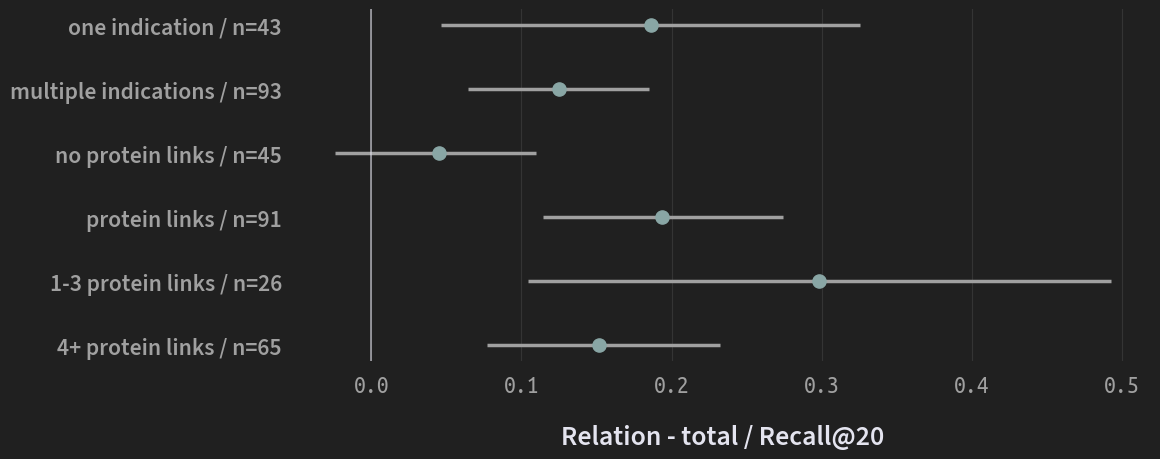

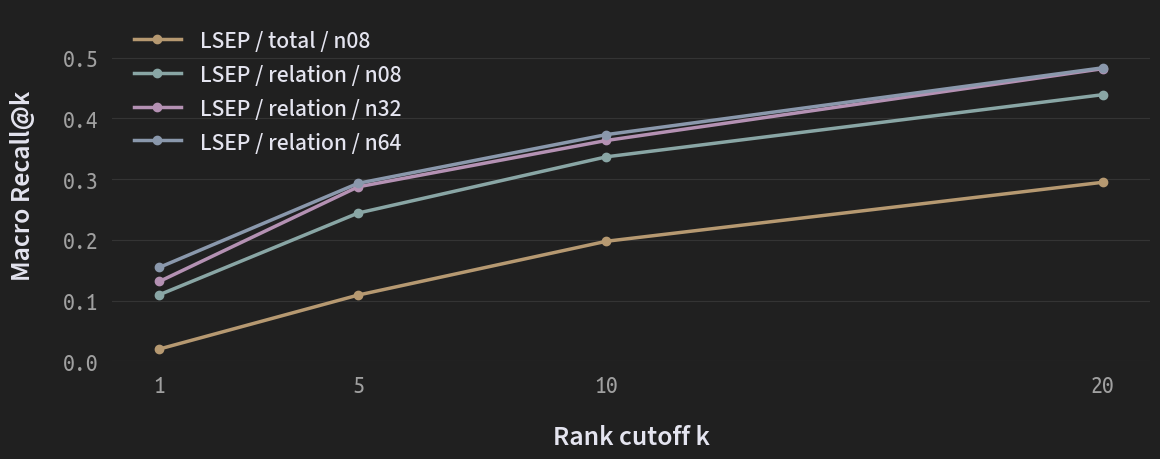

In [10]:
rows = [row for row in subgroups if row["metric"] == "recall@20"]
fig, ax = plt.subplots(figsize=(12, 5.0))
for i, row in enumerate(rows):
    ax.hlines(i, row["lower95"], row["upper95"], color=P["muted"], linewidth=2.5)
    ax.scatter(row["difference"], i, color=P["cyan"], s=90, zorder=3)
ax.axvline(0, color=P["fg"], alpha=0.65, linewidth=1.2)
ax.set_yticks(range(len(rows)), [f'{r["subgroup"]} / n={r["n"]}' for r in rows], fontweight="semibold")
ax.invert_yaxis()
ax.set(xlabel="Relation - total / Recall@20")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "subgroups")

fig, ax = plt.subplots(figsize=(12, 5.0))
for run, color, label in (
    (RUNS[0], P["orange"], "LSEP / total / n08"),
    (RUNS[1], P["cyan"], "LSEP / relation / n08"),
    (RUNS[2], P["pink"], "LSEP / relation / n32"),
    (RUNS[3], P["blue"], "LSEP / relation / n64"),
):
    rows = [row for row in cutoffs if row["run"] == run]
    ax.plot([row["k"] for row in rows], [row["recall"] for row in rows],
            color=color, linewidth=2.5, marker="o", markersize=6, label=label)
ax.set(xticks=CUTS, xlabel="Rank cutoff k", ylabel="Macro Recall@k", ylim=(0, 0.58))
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=P["fg"], loc="upper left")
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "cutoffs")

In [11]:
archive = shutil.make_archive(str(ROOT / "exapt-cases"), "zip", OUT)
print(f"export   {archive}")
files.download(archive)

export   /content/exapt-cases/exapt-cases.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>